In [47]:

import pandas as pd
import numpy as np
#  Load essential data analysis libraries:
# - pandas (pd): for loading, cleaning, and managing tabular survey data
# - numpy (np): for mathematical operations and defining missing values (NaN)


In [48]:
#Load raw dataset 

# WVS_Survey_Trimmed_2.csv = the original trimmed data + Q260 (gender), Q262 (age), Q275 (education)
df_raw = pd.read_csv('../data/raw/WVS_Survey_Trimmed_2.csv', low_memory=False)


In [49]:
# Define the list of essential variables needed for the analysis
need = ['B_COUNTRY_ALPHA', 'W_WEIGHT', 'Q51', 'Q53', 'Q54', 'Q55']

# Check for missing columns in the raw DataFrame (returns [] if all columns exist)
print([c for c in need if c not in df_raw.columns])   # should print []

[]


In [50]:

# selecting core required variables 
need = ['B_COUNTRY_ALPHA', 'W_WEIGHT', 'Q51', 'Q53', 'Q54', 'Q55']
df = df_raw[need].copy()

# make sure the survey items and weight are numeric
for c in ['W_WEIGHT', 'Q51', 'Q53', 'Q54', 'Q55']:
    df[c] = pd.to_numeric(df[c], errors='coerce')

# WVS missing codes (all negative) -> NaN
items = {'Q51': 'food', 'Q53': 'medicine', 'Q54': 'cash_income', 'Q55': 'shelter'}
for q in items:
    df[q] = df[q].where(df[q] > 0)

# recoding country codes into country names 
country_map = {
    'MMR': 'Myanmar', 'IDN': 'Indonesia', 'MYS': 'Malaysia',
    'PHL': 'Philippines', 'SGP': 'Singapore', 'VNM': 'Vietnam', 'THA': 'Thailand'
}
sea = df[df['B_COUNTRY_ALPHA'].isin(country_map)].copy()

# 1=Often, 2=Sometimes, 3=Rarely, 4=Never -> 4,3,2,1
for q in items:
    sea[q] = 5 - sea[q]

In [51]:
# Generate a summary frequency table for all hardship items (Q51, Q53, Q54, Q55)
# Checks category distribution (1-4) and counts missing values (NaN) per column
print(sea[list(items)].apply(lambda s: s.value_counts(dropna=False).sort_index()))

      Q51   Q53   Q54   Q55
1.0  7690  6808  6182  9611
2.0  1703  2380  2211  1035
3.0  1640  1745  2415   633
4.0   585   677   806   332
NaN     7    15    11    14


In [52]:
# Helper function to compute weighted mean for a column while ignoring missing values
def wmean(g, col):
    # Remove rows where either the variable or survey weight is NaN
    g = g.dropna(subset=[col, 'W_WEIGHT'])
    # Calculate weighted average using NumPy
    return np.average(g[col], weights=g['W_WEIGHT'])

# Calculate weighted average for each hardship item across each SEA country
res = pd.DataFrame({
    name: {c: wmean(g, q) for c, g in sea.groupby('B_COUNTRY_ALPHA')}
    for q, name in items.items()
})

# Rename row indices from 3-letter alpha codes (e.g., 'SGP') to full country names ('Singapore')
res.index = res.index.map(country_map)

# Display final summary table with values rounded to 3 decimal places
res.round(3)

# The higher the score, the higher the economic hardship in the country

,food,medicine,cash_income,shelter
Indonesia,1.886,2.115,1.968,1.308
Myanmar,1.346,1.282,1.882,1.231
Malaysia,1.460,1.617,1.788,1.313
Philippines,1.893,1.990,2.129,1.388
Singapore,1.128,1.155,1.301,1.064
Thailand,1.811,1.780,2.020,1.613
Vietnam,1.214,1.369,1.612,1.068


In [53]:
#calculating the mean deprivation score 
res['deprivation_mean'] = res.mean(axis=1)
res.round(3)

,food,medicine,cash_income,shelter,deprivation_mean
Indonesia,1.886,2.115,1.968,1.308,1.819
Myanmar,1.346,1.282,1.882,1.231,1.435
Malaysia,1.460,1.617,1.788,1.313,1.545
Philippines,1.893,1.990,2.129,1.388,1.850
Singapore,1.128,1.155,1.301,1.064,1.162
Thailand,1.811,1.780,2.020,1.613,1.806
Vietnam,1.214,1.369,1.612,1.068,1.316


In [54]:
#saving the mean deprivation score of each country as a dataframe
deprivation_df = (
    res[['deprivation_mean']]
    .round(3)
    .reset_index()
    .rename(columns={'index': 'country'})
    .sort_values('deprivation_mean', ascending=False)
    .reset_index(drop=True)
)
deprivation_df

,country,deprivation_mean
0,Philippines,1.850
1,Indonesia,1.819
2,Thailand,1.806
3,Malaysia,1.545
4,Myanmar,1.435
5,Vietnam,1.316
6,Singapore,1.162


# Ethical Values and Norms Q177 - 181
Creating column headers for output table based on question numbers.

In [55]:
# Q177-181: justifiability of economic norm violations (1 = Never justifiable, 10 = Always justifiable)
questions = {
    'Q177': 'benefits',         # Claiming government benefits you're not entitled to
    'Q178': 'fare_avoidance',   # Avoiding a fare on public transport
    'Q179': 'stealing',         # Stealing property
    'Q180': 'tax_cheating',     # Cheating on taxes if you have a chance
    'Q181': 'bribery'           # Someone accepting a bribe in the course of their duties
}

Map the abbreviations for the countries to their actual names.

In [ ]:
sea_countries = {
    'IDN': 'Indonesia',
    'MMR': 'Myanmar',
    'MYS': 'Malaysia',
    'PHL': 'Philippines',
    'SGP': 'Singapore',
    'THA': 'Thailand',
    'VNM': 'Vietnam'
}f


Filtering our dataset file to the 7 Southeast Asian countries above.

In [57]:
df = df_raw[df_raw['B_COUNTRY_ALPHA'].isin(sea_countries.keys())].copy()

Filtering out missing or 'don't know' responses, keeping only valid answers. Then we calculate the weighted average of the responses, using each respondent's survey weight as provided in the dataset (W_WEIGHT) to correct for sampling design.

In [58]:
def weighted_mean(group, col):
    valid = group[group[col] > 0]   # drop negative missing/don't-know codes
    return np.average(valid[col], weights=valid['W_WEIGHT'])

Calculating the weighted mean for each question, separately for each country.

In [59]:
results = {}
for q_col, label in questions.items():
    results[label] = df.groupby('B_COUNTRY_ALPHA').apply(lambda g: weighted_mean(g, q_col))

Lastly, we organise the results into a table.

In [60]:
result_df = pd.DataFrame(results)
result_df.index = result_df.index.map(sea_countries)
result_df = result_df.round(3)
print(result_df)

                 benefits  fare_avoidance  stealing  tax_cheating  bribery
B_COUNTRY_ALPHA                                                           
Indonesia           3.343           2.802     1.583         2.582    1.939
Myanmar             3.655           3.161     1.489         1.622    1.722
Malaysia            4.395           3.979     3.100         3.409    3.085
Philippines         5.211           4.805     3.646         4.041    4.104
Singapore           2.534           1.823     1.351         1.538    1.412
Thailand            2.223           2.231     1.832         1.744    1.774
Vietnam             4.524           3.424     2.495         2.832    2.898


# Personal norms 


Focus on only the columns that are related to Personal norms and calling is 'q_cols'

In [61]:
# Use the Q182-Q195 columns only
q_cols = [f"Q{i}" for i in range(182, 196)]

Data cleaning: removal of missing code and changing variable type to numeric 

In [62]:
# FIX (controls notebook): df_sea and country_col were never defined, so this cell
# crashed on a fresh run. df_sea is the 7-country subset created above.
df_sea = df.copy()
country_col = 'B_COUNTRY_ALPHA'

#change the variable into numeric and remove missing code
df_sea[q_cols] = df_sea[q_cols].apply(pd.to_numeric, errors="coerce")
df_sea[q_cols] = df_sea[q_cols].where(df_sea[q_cols] > 0)

Printing the mean column for every question for the respective countries 

In [63]:
question_means = df_sea.groupby(country_col)[q_cols].mean()
print(question_means.round(2))

                 Q182  Q183  Q184  Q185  Q186  Q187  Q188  Q189  Q190  Q191  \
B_COUNTRY_ALPHA                                                               
IDN              1.61  1.57  1.58  2.69  1.64  1.48  2.19  1.67  2.44  1.86   
MMR              1.72  1.85  1.41  2.45  1.63  1.36  1.95  1.53  5.04  1.44   
MYS              3.59  3.39  3.52  4.64  3.82  3.15  3.95  3.13  4.47  3.28   
PHL              4.57  3.77  3.02  4.20  4.31  3.13  3.62  3.44  3.96  3.73   
SGP              3.45  2.78  3.29  4.21  4.04  2.46  4.19  1.32  3.36  1.58   
THA              4.21  2.49  2.39  4.58  4.48  2.49  2.76  2.00  2.32  1.90   
VNM              5.64  3.95  4.17  5.23  5.53  4.47  4.88  2.80  4.54  3.05   

                 Q192  Q193  Q194  Q195  
B_COUNTRY_ALPHA                          
IDN              1.73  1.52  1.78  3.38  
MMR              1.55  1.39  1.43  3.93  
MYS              3.10  3.59  3.15  4.58  
PHL              4.18  3.87  3.99  4.13  
SGP              1.30  2.87  1.55  4

# Rebased PV & EV scores OLS for pooled 7 countries

In [64]:
import pandas as pd
import numpy as np

# Start from 'sea' (already has hardship recoded, SEA only)
df_individual = sea.copy()

# Add ethics items (Q177-Q181) from df_raw
ethics_cols = ['Q177', 'Q178', 'Q179', 'Q180', 'Q181']
for col in ethics_cols:
    raw_col = pd.to_numeric(df_raw.loc[df_individual.index, col], errors='coerce')
    df_individual[col] = raw_col.where(raw_col > 0)

# Create individual indices, all rebased to 20
hardship_items = ['Q51', 'Q53', 'Q54', 'Q55']
df_individual['deprivation_mean'] = df_individual[hardship_items].mean(axis=1, skipna=True)   # 1-4
df_individual['deprivation_rebased20'] = df_individual['deprivation_mean'] * 5               # 5-20

EV_raw = df_individual[ethics_cols].mean(axis=1, skipna=True)                                 # 1-10
df_individual['EV_rebased20'] = EV_raw * 2                                                    # 2-20

# Drop missing values
df_model = df_individual.dropna(subset=['deprivation_rebased20', 'EV_rebased20', 'W_WEIGHT'])

print(f"✅ df_model created!")
print(f"   N = {len(df_model)} individuals")
print(f"   Countries: {df_model['B_COUNTRY_ALPHA'].unique()}")

✅ df_model created!
   N = 11601 individuals
   Countries: <ArrowStringArray>
['IDN', 'MMR', 'MYS', 'PHL', 'SGP', 'THA', 'VNM']
Length: 7, dtype: str


# OLS Output - Individual Countries

In [65]:

# THIS IS FOR HARDSHIP AND ECONOMIC NORMS (both rebased to 20)
import statsmodels.formula.api as smf

results_by_country = {}

for country in df_model['B_COUNTRY_ALPHA'].unique():
    df_country = df_model[df_model['B_COUNTRY_ALPHA'] == country].copy()

    if len(df_country) < 100:
        print(f"\n{country}: N={len(df_country)} (too small, skipping)")
        continue

    model = smf.ols(
        "EV_rebased20 ~ deprivation_rebased20",
        data=df_country
    ).fit(weights=df_country['W_WEIGHT'])

    results_by_country[country] = model

    print(f"\n{'='*70}")
    print(f"{country} (N={len(df_country)})")
    print('='*70)
    print(model.summary())

with open('../output/tables/country_regressions_economic.txt', 'w') as f:
    for country, model in results_by_country.items():
        f.write(f"{'='*70}\n{country}\n{'='*70}\n")
        f.write(str(model.summary()))
        f.write('\n\n')

print("\nSaved: country_regressions_economic.txt")


IDN (N=3199)
                            OLS Regression Results                            
Dep. Variable:           EV_rebased20   R-squared:                       0.034
Model:                            OLS   Adj. R-squared:                  0.034
Method:                 Least Squares   F-statistic:                     113.7
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           4.09e-26
Time:                        15:20:44   Log-Likelihood:                -8178.2
No. Observations:                3199   AIC:                         1.636e+04
Df Residuals:                    3197   BIC:                         1.637e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept       

In [66]:
q_cols_personal = [f"Q{i}" for i in range(182, 196)]

# bring in the Q182-195 columns from df_raw, matched by respondent
df_model = df_model.join(df_raw.loc[df_model.index, q_cols_personal])

# clean: numeric + drop missing codes
df_model[q_cols_personal] = df_model[q_cols_personal].apply(pd.to_numeric, errors='coerce')
df_model[q_cols_personal] = df_model[q_cols_personal].where(df_model[q_cols_personal] > 0)

# average across the 14 items per respondent (1-10), then rebase to 20 (2-20)
df_model['PV_mean'] = df_model[q_cols_personal].mean(axis=1)
df_model['PV_rebased20'] = df_model['PV_mean'] * 2

print(df_model[['PV_rebased20']].describe())

       PV_rebased20
count  11599.000000
mean       5.763104
std        3.432116
min        2.000000
25%        3.142857
50%        4.714286
75%        7.714286
max       20.000000


In [67]:
results_by_country_personal = {}

print("="*70)
print("INDIVIDUAL-LEVEL OLS: Deprivation -> Personal Norm Violations (both rebased to 20)")
print("="*70)

for country in df_model['B_COUNTRY_ALPHA'].unique():
    df_country = df_model[df_model['B_COUNTRY_ALPHA'] == country].copy()
    if len(df_country) < 100:
        print(f"\n⚠️  {country}: N={len(df_country)} (too small, skipping)")
        continue
    model = smf.ols("PV_rebased20 ~ deprivation_rebased20", data=df_country).fit(weights=df_country['W_WEIGHT'])
    results_by_country_personal[country] = model
    print(f"\n{country} (N={len(df_country)})")
    print(model.summary())

with open('../output/tables/country_regressions_personal.txt', 'w') as f:
    for country, model in results_by_country_personal.items():
        f.write(f"{'='*70}\n{country}\n{'='*70}\n")
        f.write(str(model.summary()))
        f.write('\n\n')

print("\nSaved: country_regressions_personal.txt")

INDIVIDUAL-LEVEL OLS: Deprivation -> Personal Norm Violations (both rebased to 20)

IDN (N=3199)
                            OLS Regression Results                            
Dep. Variable:           PV_rebased20   R-squared:                       0.010
Model:                            OLS   Adj. R-squared:                  0.009
Method:                 Least Squares   F-statistic:                     31.63
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           2.02e-08
Time:                        15:20:44   Log-Likelihood:                -7276.9
No. Observations:                3198   AIC:                         1.456e+04
Df Residuals:                    3196   BIC:                         1.457e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------

In [68]:
# Comparison of OLS (both DVs and the IV rebased to 20, so betas are directly comparable)
term = 'deprivation_rebased20'
comparison_clean = pd.DataFrame({
    country: {
        'Economic Norms: β (coefficient)': results_by_country[country].params[term],
        'Economic Norms: p-value': results_by_country[country].pvalues[term],
        'Economic Norms: Significant?': 'Yes' if results_by_country[country].pvalues[term] < 0.05 else 'No',
        'Personal Norms: β (coefficient)': results_by_country_personal[country].params[term],
        'Personal Norms: p-value': results_by_country_personal[country].pvalues[term],
        'Personal Norms: Significant?': 'Yes' if results_by_country_personal[country].pvalues[term] < 0.05 else 'No',
    }
    for country in results_by_country
}).T

num_cols = ['Economic Norms: β (coefficient)', 'Economic Norms: p-value',
            'Personal Norms: β (coefficient)', 'Personal Norms: p-value']
comparison_clean[num_cols] = comparison_clean[num_cols].astype(float).round(4)

print(comparison_clean)
comparison_clean.to_csv('../output/tables/individual_level_comparison.csv')

     Economic Norms: β (coefficient)  Economic Norms: p-value  \
IDN                           0.1776                   0.0000   
MMR                           0.1193                   0.0000   
MYS                           0.2526                   0.0000   
PHL                           0.0855                   0.0233   
SGP                           0.2634                   0.0000   
THA                           0.1571                   0.0000   
VNM                           0.0282                   0.5266   

    Economic Norms: Significant?  Personal Norms: β (coefficient)  \
IDN                          Yes                           0.0707   
MMR                          Yes                           0.0411   
MYS                          Yes                           0.2139   
PHL                          Yes                           0.0430   
SGP                          Yes                           0.0423   
THA                          Yes                           0.0044

# OLS in graph form

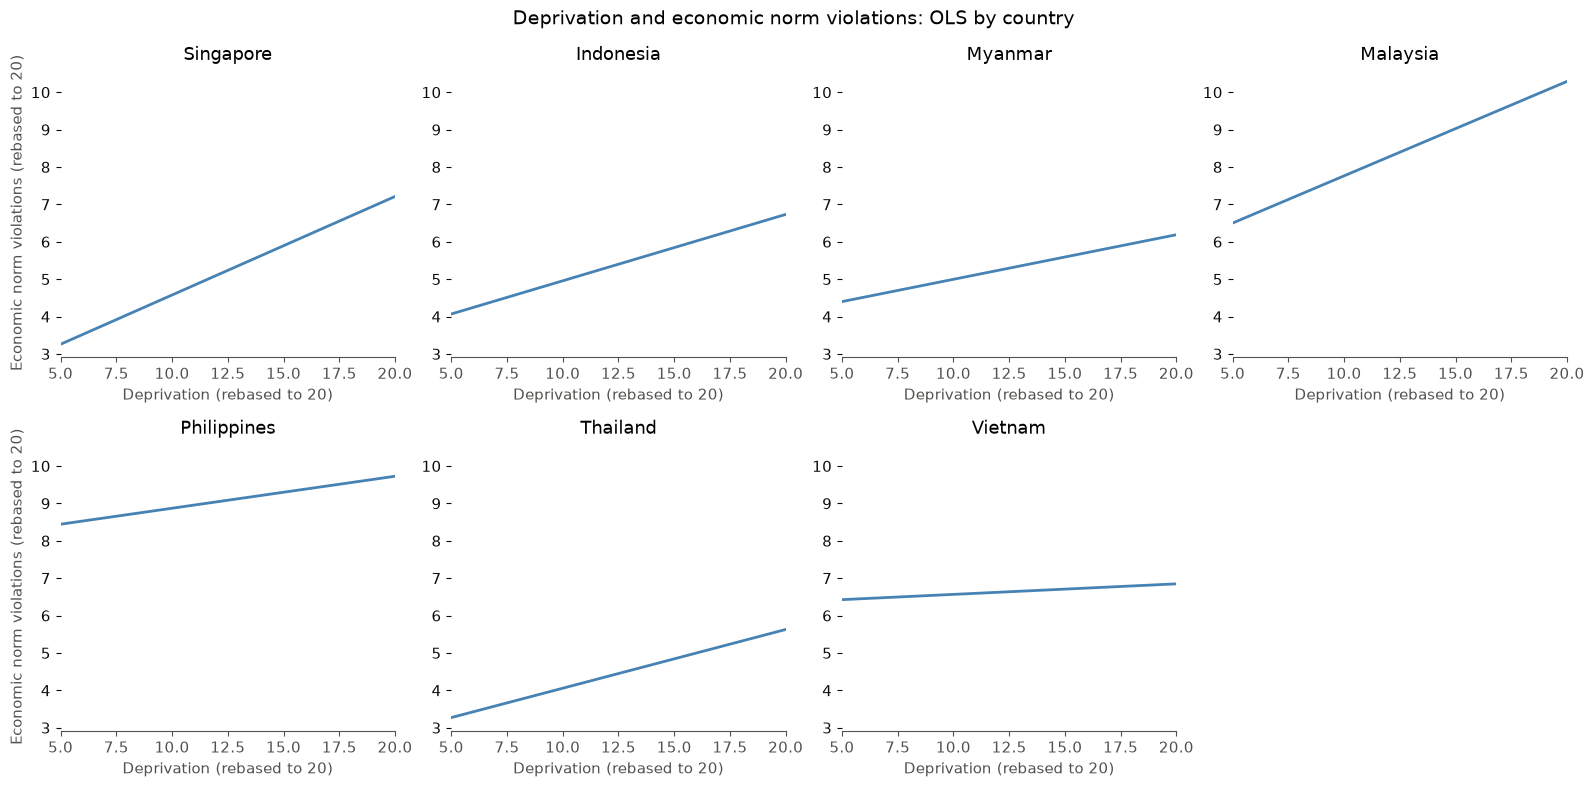

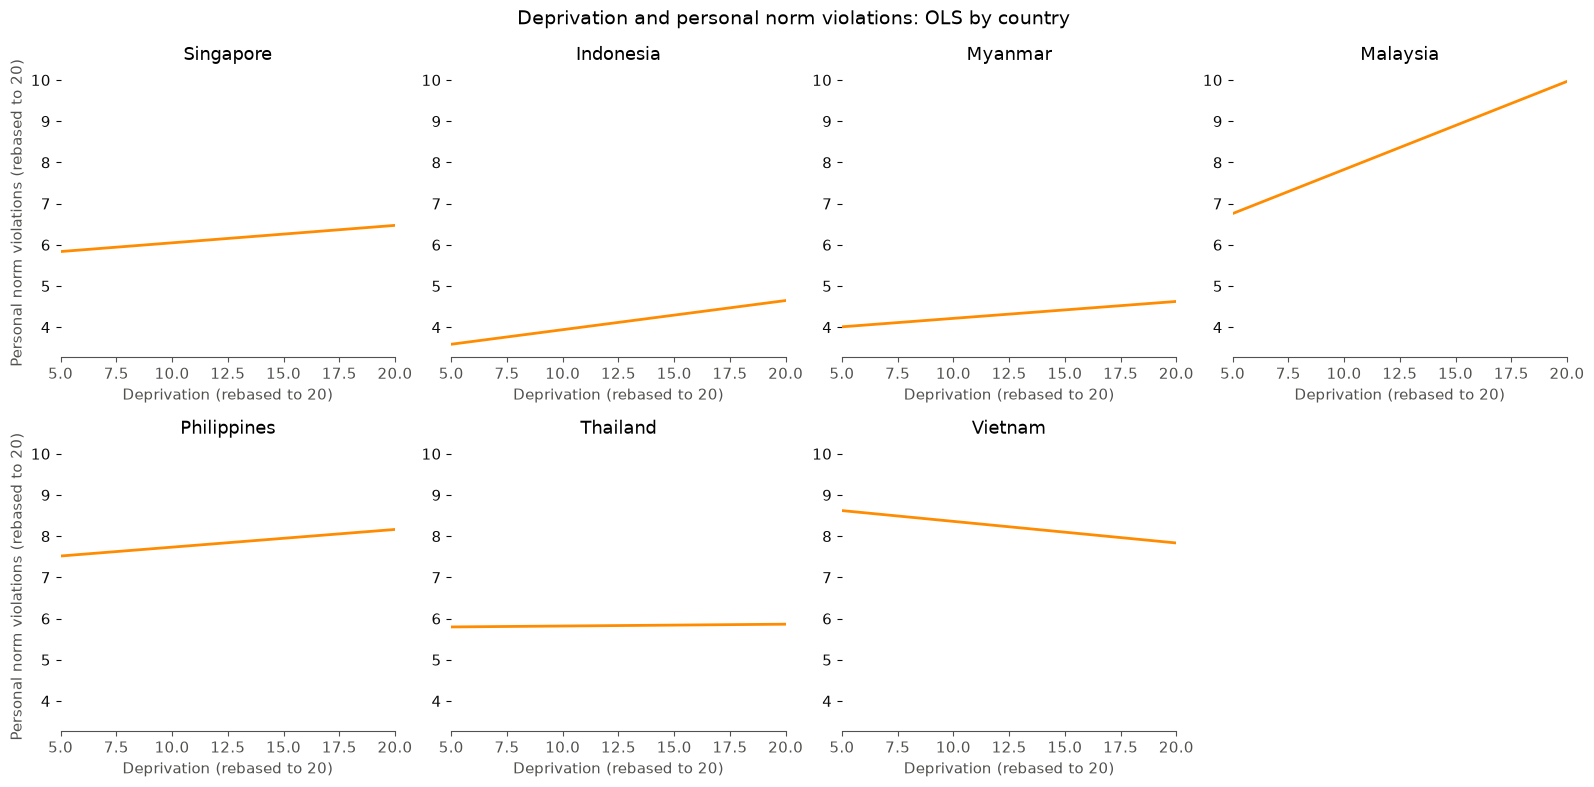

In [69]:
# Same y-axis on every panel so slopes can be compared across countries
# Regression lines for the individual-level country OLS models, one panel per country
# (uses results_by_country and results_by_country_personal, the same models
#  as the saved OLS tables; everything rebased to 20)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

country_names = {
    'IDN': 'Indonesia', 'MMR': 'Myanmar', 'MYS': 'Malaysia',
    'PHL': 'Philippines', 'SGP': 'Singapore', 'THA': 'Thailand', 'VNM': 'Vietnam'
}
order = ['SGP', 'IDN', 'MMR', 'MYS', 'PHL', 'THA', 'VNM']


def plot_country_regressions(results, y_label, color, title, filename):
    x = pd.DataFrame({'deprivation_rebased20': np.linspace(5, 20, 50)})
    fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharey=True)
    axes = axes.ravel()
    for ax, c in zip(axes, order):
        ax.plot(x['deprivation_rebased20'], results[c].predict(x), color=color, linewidth=2)
        ax.set_title(country_names[c])
        ax.set_xlim(5, 20)
        ax.set_xlabel('Deprivation (rebased to 20)')
    axes[-1].axis('off')   # 7 countries, 8 panels
    axes[0].set_ylabel(y_label)
    axes[4].set_ylabel(y_label)
    for ax in axes[:7]:
        ax.tick_params(labelleft=True)   # show y numbers on every panel
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.savefig(f'../output/figures/{filename}', dpi=200, bbox_inches='tight')
    plt.show()


plot_country_regressions(results_by_country, 'Economic norm violations (rebased to 20)', 'steelblue',
                         'Deprivation and economic norm violations: OLS by country',
                         'country_regressions_economic.png')

plot_country_regressions(results_by_country_personal, 'Personal norm violations (rebased to 20)', 'darkorange',
                         'Deprivation and personal norm violations: OLS by country',
                         'country_regressions_personal.png')

# Pooled OLS - All 7 Countries 


In [70]:
import statsmodels.formula.api as smf

model_econ_pooled_simple_rebased = smf.ols(
    "EV_rebased20 ~ deprivation_rebased20",
    data=df_model
).fit(weights=df_model['W_WEIGHT'])
print("=== Economic Norms (Pooled, Rebased 0-20) ===")
print(model_econ_pooled_simple_rebased.summary())

model_pers_pooled_simple_rebased = smf.ols(
    "PV_rebased20 ~ deprivation_rebased20",
    data=df_model
).fit(weights=df_model['W_WEIGHT'])
print("\n=== Personal Norms (Pooled, Rebased 0-20) ===")
print(model_pers_pooled_simple_rebased.summary())

=== Economic Norms (Pooled, Rebased 0-20) ===
                            OLS Regression Results                            
Dep. Variable:           EV_rebased20   R-squared:                       0.034
Model:                            OLS   Adj. R-squared:                  0.034
Method:                 Least Squares   F-statistic:                     407.8
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           3.81e-89
Time:                        15:20:45   Log-Likelihood:                -31090.
No. Observations:               11601   AIC:                         6.218e+04
Df Residuals:                   11599   BIC:                         6.220e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------

# Comparison Graph 

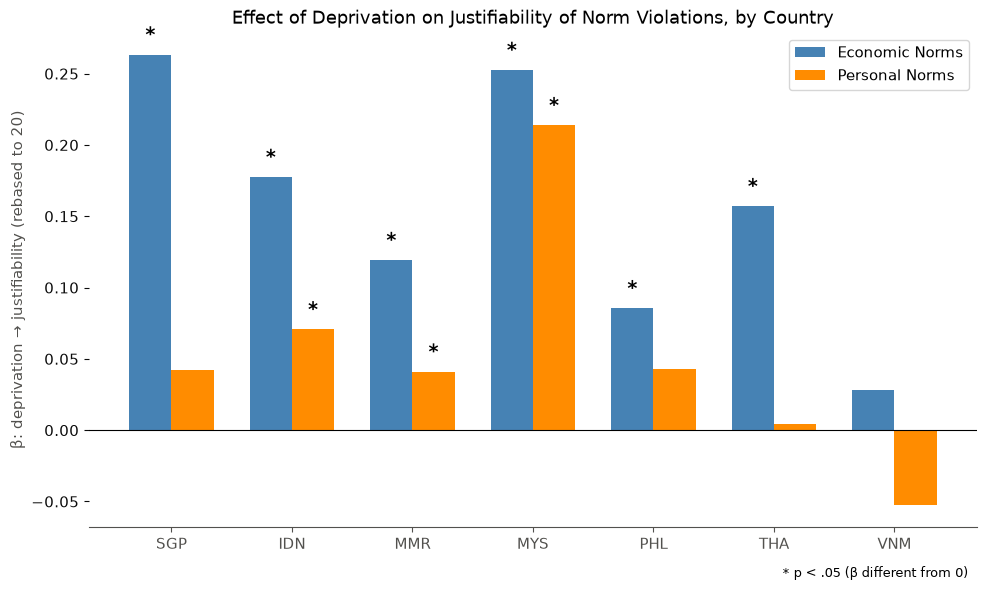

In [71]:
# Bar chart of each country's own beta (not relative to Singapore)
# FIX (controls notebook): results_by_country_rebased_econ/_pers were never defined,
# so this cell crashed on a fresh run. The per-country models above are the same
# rebased-to-20 models: results_by_country and results_by_country_personal.
import matplotlib.pyplot as plt
import numpy as np

countries = ['SGP', 'IDN', 'MMR', 'MYS', 'PHL', 'THA', 'VNM']
term = 'deprivation_rebased20'


def get_stats(results):
    b = np.array([results[c].params[term] for c in countries])
    p = np.array([results[c].pvalues[term] for c in countries])
    return b, p


econ_b, econ_p = get_stats(results_by_country)
pers_b, pers_p = get_stats(results_by_country_personal)

x = np.arange(len(countries))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, econ_b, width, label='Economic Norms', color='steelblue')
bars2 = ax.bar(x + width/2, pers_b, width, label='Personal Norms', color='darkorange')


# * = beta significantly different from zero (p < .05)
def star(bars, b, p):
    for i, bar in enumerate(bars):
        if p[i] < 0.05:
            y = b[i] + 0.01 if b[i] >= 0 else b[i] - 0.02
            ax.text(bar.get_x() + bar.get_width() / 2, y, '*',
                    ha='center', fontsize=14, fontweight='bold')


star(bars1, econ_b, econ_p)
star(bars2, pers_b, pers_p)

ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(countries)
ax.set_ylabel('β: deprivation → justifiability (rebased to 20)')
ax.set_title('Effect of Deprivation on Justifiability of Norm Violations, by Country')
ax.legend()
ax.text(0.99, -0.1, '* p < .05 (β different from 0)',
        transform=ax.transAxes, ha='right', fontsize=9)
plt.tight_layout()

plt.savefig('../output/figures/country_betas_by_norm_type.png', dpi=200, bbox_inches='tight')
plt.show()

# Controls, adjusted OLS and forest plots

**Prof's feedback:** no control variables, and a forest plot would show the results better than the bar chart.

**Model sequence.** Each step adds controls to the one before. Every step uses the *same respondents*, so a change in β comes from the controls and not from a change in sample.

| Model | Adds | Why it is a confounder |
|---|---|---|
| M0 | deprivation only | Baseline, same as the earlier models |
| M1 | income scale (Q288), subjective class (Q287) | Separates *insecurity* from *economic position*. Our slides define insecurity as distinct from income level, so this is the control our concept needs |
| M2 | religiosity (from Q6, Q171, Q173 via the WVS indices) | Religiosity is related to hardship and strongly shapes moral judgement, especially on personal norms |
| M3 | age (Q262), gender (Q260), education (Q275) | Standard demographic confounders. They are related to both economic position and moral attitudes, and they are not caused by current deprivation in the way later attitudes could be |

Pooled models also include country fixed effects, so they compare respondents *within* the same country.

**Country fixed effects use effect coding, so there is no reference country.** Each country's coefficient is how far its average justifiability sits above (+) or below (−) the average of the seven countries, after the other variables are taken into account. Each country counts equally in that average. Effect coding changes only the country coefficients: β on deprivation, the controls and R² are the same as with a reference country. The interaction model further down is the exception, and keeps Singapore as the baseline, as requested in the earlier feedback.

**Scale.** Scaled controls are rebased to a maximum of 20 to match deprivation and the DVs, using the same multiply-up method: income × 2 (2-20), subjective class × 4 (4-20), religiosity × 20 (0-20), education × 2.5 (0-20), age × 20/oldest age in the sample (oldest = 20). Gender stays 0/1 because it is a category, so its β is the female-male difference.

**Not used as controls**
- `SACSECVAL`, `RESEMAVAL`, `RELATIVISM`, `CHOICE`, `I_NORM1-3`, `I_HOMOLIB`, `I_ABORTLIB`, `I_DIVORLIB`: these are built partly from our own DV items, so controlling for them would be controlling for the outcome.
- `Y001`-`Y003` (postmaterialism and autonomy): plausibly a result of insecurity rather than a cause, so they could be mediators. `Y003` is also 16-41% missing.
- Country-level measures such as GDP or Gini: constant within a country, so absorbed by country fixed effects.

**Estimation.** Survey-weighted least squares with heteroskedasticity-robust (HC1) standard errors.

In [72]:
# WEIGHTS CHECK: fit(weights=...) on smf.ols is silently ignored.
# The earlier cells use that pattern, so those models are unweighted.
# This section uses smf.wls(..., weights=...), which applies them.
import statsmodels.formula.api as smf

sgp = df_model[df_model['B_COUNTRY_ALPHA'] == 'SGP']
check = pd.Series({
    'smf.ols(...).fit(weights=W_WEIGHT)': smf.ols('EV_rebased20 ~ deprivation_rebased20', data=sgp).fit(weights=sgp['W_WEIGHT']).params.iloc[1],
    'smf.ols(...).fit() [no weights]':    smf.ols('EV_rebased20 ~ deprivation_rebased20', data=sgp).fit().params.iloc[1],
    'smf.wls(..., weights=W_WEIGHT).fit()': smf.wls('EV_rebased20 ~ deprivation_rebased20', data=sgp, weights=sgp['W_WEIGHT']).fit().params.iloc[1],
}, name='Singapore β')
print(check.round(4).to_string())

smf.ols(...).fit(weights=W_WEIGHT)      0.2634
smf.ols(...).fit() [no weights]         0.2634
smf.wls(..., weights=W_WEIGHT).fit()    0.2675


## Step 1: Build the control variables

In [73]:
df_ctrl = df_model.copy()
raw = df_raw.loc[df_ctrl.index]
num = lambda col: pd.to_numeric(raw[col], errors='coerce')

# Income: Q288, 1 = lowest income group ... 10 = highest income group
# Rebased to 20: 1-10 x 2 = 2-20
df_ctrl['income'] = num('Q288').where(lambda s: s > 0) * 2

# Subjective class: Q287 is 1 = upper ... 5 = lower. Reversed so higher = higher class
# Rebased to 20: 1-5 x 4 = 4-20
df_ctrl['subj_class'] = (6 - num('Q287').where(lambda s: s > 0)) * 4

# Religiosity: the WVS I_RELIG* items run 0-1 in the INVERSE direction
# (1 = religion unimportant / not religious / never attends), so we flip the mean.
# Result: 0-1, then rebased to 20: 0 = least religious ... 20 = most religious
rel_items = ['I_RELIGIMP', 'I_RELIGBEL', 'I_RELIGPRAC']
for c in rel_items:
    df_ctrl[c] = num(c).where(lambda s: s >= 0)
df_ctrl['religiosity'] = (1 - df_ctrl[rel_items].mean(axis=1, skipna=True)) * 20

# Demographics: Q260, Q262, Q275 come from WVS_Survey_Trimmed_2.csv
# Age: Q262 in years, rebased so the oldest respondent = 20
age = num('Q262').where(lambda s: s > 0)
df_ctrl['age'] = age * 20 / age.max()

# Education: Q275 ISCED 0-8, rebased to 20: 0-8 x 2.5 = 0-20
df_ctrl['education'] = num('Q275').where(lambda s: s >= 0) * 2.5

# Gender: Q260 1 = male, 2 = female. Kept as 0/1 because it is a category
sex = num('Q260').where(lambda s: s > 0)
df_ctrl['female'] = (sex == 2).astype(float).where(sex.notna())

# Within-person gap between the two DVs. β on this outcome = β(economic) - β(personal),
# and its CI accounts for the same people answering both sets of questions.
df_ctrl['gap_EV_PV'] = df_ctrl['EV_rebased20'] - df_ctrl['PV_rebased20']
df_ctrl['country'] = df_ctrl['B_COUNTRY_ALPHA'].astype(str)

# Model sequence
control_sets = {
    'M0': [],
    'M1': ['income', 'subj_class'],
    'M2': ['income', 'subj_class', 'religiosity'],
    'M3': ['income', 'subj_class', 'religiosity', 'age', 'female', 'education'],
}
FULL = list(control_sets)[-1]
all_controls = control_sets[FULL]

print(df_ctrl[['deprivation_rebased20', 'EV_rebased20', 'PV_rebased20', 'income', 'subj_class', 'religiosity', 'age', 'education', 'female']].agg(['min', 'max']).round(1).to_string())

# Same complete cases for every model, so M0 and the full model are comparable
analysis = df_ctrl.dropna(subset=['deprivation_rebased20', 'EV_rebased20', 'PV_rebased20', 'W_WEIGHT'] + all_controls).copy()
n_table = pd.DataFrame({'before': df_ctrl['country'].value_counts(), 'after': analysis['country'].value_counts()})
n_table['dropped'] = n_table['before'] - n_table['after']
print(f'\nFull model: {FULL}. Respondents kept: {len(analysis)} of {len(df_ctrl)}')
print(n_table.sort_index().to_string())

     deprivation_rebased20  EV_rebased20  PV_rebased20  income  subj_class  religiosity   age  education  female
min                    5.0           2.0           2.0     2.0         4.0          0.0   3.5        0.0     0.0
max                   20.0          20.0          20.0    20.0        20.0         20.0  20.0       20.0     1.0

Full model: M3. Respondents kept: 11419 of 11601
         before  after  dropped
country                        
IDN        3199   3127       72
MMR        1200   1198        2
MYS        1313   1313        0
PHL        1200   1199        1
SGP        2004   1925       79
THA        1485   1457       28
VNM        1200   1200        0


## Step 2: Check the variables

Scale reliability (Cronbach's α, requested in earlier feedback), weighted means by country, and collinearity.

In [74]:
def cronbach_alpha(items):
    x = items.dropna()
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

scales = {
    'Deprivation (Q51, Q53-55)': ['Q51', 'Q53', 'Q54', 'Q55'],
    'Economic violations (Q177-181)': ethics_cols,
    'Personal violations (Q182-195)': q_cols_personal,
    'Religiosity (3 items)': rel_items,
}
alpha = pd.DataFrame({name: {**{'All countries': cronbach_alpha(analysis[cols])},
                             **{c: cronbach_alpha(g[cols]) for c, g in analysis.groupby('country')}}
                      for name, cols in scales.items()}).T
print("Cronbach's alpha")
print(alpha.round(2).to_string())

Cronbach's alpha
                                All countries   IDN   MMR   MYS   PHL   SGP   THA   VNM
Deprivation (Q51, Q53-55)                0.75  0.61  0.66  0.83  0.65  0.76  0.88  0.62
Economic violations (Q177-181)           0.81  0.68  0.59  0.88  0.72  0.80  0.87  0.80
Personal violations (Q182-195)           0.91  0.87  0.77  0.95  0.90  0.89  0.86  0.88
Religiosity (3 items)                    0.70  0.11  0.22  0.58  0.27  0.76  0.35  0.63


In [75]:
# Weighted means of each variable by country
desc_vars = ['deprivation_rebased20', 'EV_rebased20', 'PV_rebased20'] + all_controls
descriptives = pd.DataFrame({
    country_names[c]: {v: np.average(g[v], weights=g['W_WEIGHT']) for v in desc_vars}
    for c, g in analysis.groupby('country')
}).T
descriptives.insert(0, 'N', analysis['country'].value_counts().rename(index=country_names))
descriptives.to_csv('../output/tables/controls_descriptives.csv')
print(descriptives.round(2).to_string())

                N  deprivation_rebased20  EV_rebased20  PV_rebased20  income  subj_class  religiosity   age  female  education
Indonesia    3127                   9.13          4.89          3.89    8.68        9.48        17.67  7.73    0.49       5.10
Myanmar      1198                   7.17          4.66          4.10    9.41       11.16        16.42  7.85    0.50       5.94
Malaysia     1313                   7.72          7.19          7.34    9.20       11.60        15.31  7.44    0.50       8.36
Philippines  1199                   9.25          8.73          7.63    8.61       10.54        16.89  8.54    0.50       5.55
Singapore    1925                   5.80          3.45          5.92   10.03       10.85        11.22  9.15    0.51      10.70
Thailand     1457                   9.05          3.91          5.83    9.48       11.06        10.16  8.50    0.53       5.79
Vietnam      1200                   6.58          6.47          8.54   10.21       10.39         7.25  7.36    

In [76]:
# Collinearity: VIF above about 5 would be a concern
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = pd.concat([analysis[['deprivation_rebased20'] + all_controls],
               pd.get_dummies(analysis['country'], drop_first=True, dtype=float)], axis=1)
X.insert(0, 'const', 1.0)
vif = pd.Series({c: variance_inflation_factor(X.values, i) for i, c in enumerate(X.columns) if c != 'const'})
print(vif.round(2).to_string())

deprivation_rebased20    1.28
income                   1.30
subj_class               1.27
religiosity              1.74
age                      1.19
female                   1.01
education                1.47
MMR                      1.30
MYS                      1.36
PHL                      1.26
SGP                      2.08
THA                      1.69
VNM                      1.87


## Step 3: OLS with controls

The same model sequence is run for each country and pooled, on three outcomes:
- **Economic**: justifiability of economic norm violations
- **Personal**: justifiability of personal norm violations
- **Gap**: economic minus personal, which tests our research question directly: is deprivation linked more strongly to economic violations than to personal ones?

In [77]:
DVS = {'Economic': 'EV_rebased20', 'Personal': 'PV_rebased20', 'Gap': 'gap_EV_PV'}
IV = 'deprivation_rebased20'
ALL = 'Pooled'
# Effect (sum-to-zero) coding: countries are compared with the 7-country average, no reference country
COUNTRY_FE = 'C(country, Sum)'


def fit_wls(dv, controls, data, country_effects=False, weights=None):
    '''Survey-weighted least squares with robust (HC1) standard errors.'''
    rhs = [IV] + controls + ([COUNTRY_FE] if country_effects else [])
    w = data['W_WEIGHT'] if weights is None else weights
    return smf.wls(f"{dv} ~ {' + '.join(rhs)}", data=data, weights=w).fit(cov_type='HC1', use_t=True)


models, rows = {}, []
for dv_label, dv in DVS.items():
    for step, controls in control_sets.items():
        groups = [(c, g) for c, g in analysis.groupby('country')] + [(ALL, analysis)]
        for country, data in groups:
            m = fit_wls(dv, controls, data, country_effects=(country == ALL))
            models[(country, dv_label, step)] = m
            lo, hi = m.conf_int().loc[IV]
            rows.append({'country': country, 'outcome': dv_label, 'model': step, 'beta': m.params[IV],
                         'se': m.bse[IV], 'ci_low': lo, 'ci_high': hi, 'p': m.pvalues[IV],
                         'n': int(m.nobs), 'r2': m.rsquared})
seq = pd.DataFrame(rows)
seq.to_csv('../output/tables/ols_controls_by_country.csv', index=False)

# Full regression output for every full-controls model
with open('../output/tables/ols_controls_full_summaries.txt', 'w') as f:
    for (country, dv_label, step), m in models.items():
        if step == FULL:
            f.write(f"{'='*78}\n{country} | {dv_label} | {step}\n{'='*78}\n{m.summary()}\n\n")

# How β on deprivation moves as controls are added
show = seq[seq['outcome'] != 'Gap'].pivot(index=['outcome', 'country'], columns='model', values='beta')
show['% change M0 to full'] = 100 * (show[FULL] - show['M0']) / show['M0'].abs()
print('β on deprivation at each step')
print(show.round(3).to_string())

β on deprivation at each step
model                M0     M1     M2     M3  % change M0 to full
outcome  country                                                 
Economic IDN      0.192  0.185  0.184  0.150              -21.928
         MMR      0.121  0.122  0.121  0.103              -14.426
         MYS      0.253  0.232  0.235  0.242               -4.352
         PHL      0.085  0.104  0.103  0.090                6.289
         Pooled   0.168  0.166  0.166  0.156               -7.263
         SGP      0.261  0.267  0.274  0.257               -1.368
         THA      0.153  0.148  0.144  0.140               -8.756
         VNM      0.028  0.054  0.068  0.062              118.944
Personal IDN      0.066  0.063  0.062  0.053              -20.084
         MMR      0.042  0.046  0.045  0.046                9.407
         MYS      0.214  0.207  0.191  0.194               -9.106
         PHL      0.041  0.064  0.064  0.049               20.951
         Pooled   0.059  0.061  0.063  0.060  

In [78]:
# R² for each model (pooled, with country fixed effects)
r2_table = seq[seq['country'] == ALL].pivot(index='outcome', columns='model', values='r2')
r2_table = r2_table.loc[['Economic', 'Personal']]
r2_table['Change M0 to full'] = r2_table[FULL] - r2_table['M0']
print('R² by model (pooled)')
print(r2_table.round(3).to_string())

# R² for the full model in each country
r2_country = seq[(seq['model'] == FULL) & (seq['outcome'] != 'Gap')].pivot(index='country', columns='outcome', values='r2')
print(f'\nR² for the full model ({FULL}) by country')
print(r2_country.round(3).to_string())

R² by model (pooled)
model        M0     M1     M2     M3  Change M0 to full
outcome                                                
Economic  0.231  0.231  0.231  0.239              0.008
Personal  0.231  0.232  0.253  0.259              0.027

R² for the full model (M3) by country
outcome  Economic  Personal
country                    
IDN         0.081     0.028
MMR         0.048     0.021
MYS         0.083     0.045
PHL         0.015     0.028
Pooled      0.239     0.259
SGP         0.083     0.263
THA         0.069     0.052
VNM         0.023     0.017


In [79]:
# Results table for the write-up: full-controls model
stars = lambda p: '***' if p < .001 else '**' if p < .01 else '*' if p < .05 else ''
full = seq[seq['model'] == FULL].copy()
full['β [95% CI]'] = full.apply(lambda r: f"{r.beta:.3f}{stars(r.p)} [{r.ci_low:.3f}, {r.ci_high:.3f}]", axis=1)
full_table = full.pivot(index='country', columns='outcome', values='β [95% CI]')[list(DVS)]
full_table['N'] = full.groupby('country')['n'].first()
full_table.to_csv('../output/tables/ols_controls_full_model_table.csv')
print(full_table.to_string())
print('\n* p < .05, ** p < .01, *** p < .001')

outcome                 Economic                 Personal                      Gap      N
country                                                                                  
IDN      0.150*** [0.102, 0.198]   0.053** [0.019, 0.087]  0.097*** [0.052, 0.143]   3127
MMR      0.103*** [0.049, 0.158]    0.046* [0.007, 0.086]    0.057* [0.003, 0.111]   1198
MYS      0.242*** [0.172, 0.311]  0.194*** [0.124, 0.265]    0.047 [-0.007, 0.102]   1313
PHL        0.090* [0.001, 0.180]    0.049 [-0.034, 0.132]    0.041 [-0.035, 0.117]   1199
Pooled   0.156*** [0.133, 0.179]  0.060*** [0.038, 0.081]  0.096*** [0.075, 0.118]  11419
SGP      0.257*** [0.180, 0.335]    0.066 [-0.008, 0.140]  0.192*** [0.113, 0.271]   1925
THA      0.140*** [0.103, 0.177]    0.003 [-0.040, 0.045]  0.137*** [0.097, 0.178]   1457
VNM        0.062 [-0.029, 0.152]   -0.038 [-0.126, 0.051]    0.099* [0.016, 0.183]   1200

* p < .05, ** p < .01, *** p < .001


In [80]:
# Pooled model output with every control shown (economic, then personal)
# All seven country rows are listed in the next cell, because effect coding shows one fewer here
for label in ['Economic', 'Personal']:
    m = models[(ALL, label, FULL)]
    print(f"\n=== Pooled {label}, {FULL} with effect-coded country fixed effects ===")
    print(m.summary().tables[1])


=== Pooled Economic, M3 with effect-coded country fixed effects ===
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  5.6339      0.225     25.094      0.000       5.194       6.074
C(country, Sum)[S.IDN]    -1.0124      0.076    -13.352      0.000      -1.161      -0.864
C(country, Sum)[S.MMR]    -0.9078      0.078    -11.710      0.000      -1.060      -0.756
C(country, Sum)[S.MYS]     1.6575      0.104     15.962      0.000       1.454       1.861
C(country, Sum)[S.PHL]     2.8792      0.125     22.979      0.000       2.634       3.125
C(country, Sum)[S.SGP]    -1.5476      0.070    -22.103      0.000      -1.685      -1.410
C(country, Sum)[S.THA]    -2.0275      0.081    -25.025      0.000      -2.186      -1.869
deprivation_rebased20      0.1560      0.012     13.168      0.000       0.133       0.179
income               

### Country effects: above or below the seven-country average

With effect coding, the model reports six country coefficients and the seventh (Vietnam) is minus their sum, because all seven deviations add up to zero. This cell calculates all seven, with confidence intervals, from the full model. The intercept is the seven-country average when every predictor is zero, so it is a reference point and is not meaningful on its own.

In [81]:
def country_effects(m, levels):
    # Every country's deviation from the 7-country average, including the one effect coding leaves out
    names = list(m.params.index)
    shown = [n for n in names if n.startswith(COUNTRY_FE + '[S.')]
    rows = []
    for lv in levels:
        r = np.zeros(len(names))
        term = f'{COUNTRY_FE}[S.{lv}]'
        if term in names:
            r[names.index(term)] = 1
        else:                                   # omitted country = -(sum of the others)
            for n in shown:
                r[names.index(n)] = -1
        t = m.t_test(r)
        lo, hi = np.asarray(t.conf_int()).ravel()
        rows.append({'country': country_names[lv], 'effect': float(np.squeeze(t.effect)), 'ci_low': lo, 'ci_high': hi,
                     'p': float(np.squeeze(t.pvalue))})
    return pd.DataFrame(rows)


levels = sorted(analysis['country'].unique())
ce = pd.concat([country_effects(models[(ALL, label, FULL)], levels).assign(outcome=label) for label in ['Economic', 'Personal']])
ce.to_csv('../output/tables/ols_controls_country_effects.csv', index=False)
ce['effect [95% CI]'] = ce.apply(lambda r: f"{r.effect:+.2f}{stars(r.p)} [{r.ci_low:+.2f}, {r.ci_high:+.2f}]", axis=1)
print('Country effects: difference from the seven-country average (justifiability score, 2-20)')
print(ce.pivot(index='country', columns='outcome', values='effect [95% CI]').to_string())
print('\nCheck: effects sum to zero ->', ce.groupby('outcome')['effect'].sum().round(10).to_dict())
print('* p < .05, ** p < .01, *** p < .001')

Country effects: difference from the seven-country average (justifiability score, 2-20)
outcome                     Economic                 Personal
country                                                      
Indonesia    -1.01*** [-1.16, -0.86]  -1.97*** [-2.10, -1.83]
Malaysia     +1.66*** [+1.45, +1.86]  +1.31*** [+1.11, +1.51]
Myanmar      -0.91*** [-1.06, -0.76]  -1.75*** [-1.87, -1.63]
Philippines  +2.88*** [+2.63, +3.12]  +1.77*** [+1.53, +2.00]
Singapore    -1.55*** [-1.68, -1.41]  -0.29*** [-0.44, -0.15]
Thailand     -2.03*** [-2.19, -1.87]  -0.75*** [-0.91, -0.59]
Vietnam      +0.96*** [+0.77, +1.15]  +1.68*** [+1.49, +1.86]

Check: effects sum to zero -> {'Economic': -0.0, 'Personal': 0.0}
* p < .05, ** p < .01, *** p < .001


### Does the deprivation slope differ by country?

The pooled model with Singapore as baseline and country × deprivation interactions, now with controls. Controls can also differ by country, because religiosity in particular does not work the same way everywhere, so these slopes match the country models above. The joint test asks whether the deprivation slope is the same in all seven countries. `Equal country weight` repeats the pooled estimate with each country counting equally, because `W_WEIGHT` alone lets larger samples such as Indonesia count for more.

In [82]:
def interaction_model(dv, data=analysis):
    base = "C(country, Treatment('SGP'))"
    terms = [f'{v} * {base}' for v in all_controls]
    f = f"{dv} ~ {IV} * {base} + " + ' + '.join(terms)
    return smf.wls(f, data=data, weights=data['W_WEIGHT']).fit(cov_type='HC1', use_t=True)


int_rows, joint = [], {}
for label in ['Economic', 'Personal']:
    m = interaction_model(DVS[label])
    int_rows.append({'outcome': label, 'term': 'Singapore slope (baseline)', 'b': m.params[IV], 'se': m.bse[IV], 'p': m.pvalues[IV]})
    terms = [t for t in m.params.index if ':' in t and IV in t]
    for t in terms:
        code = t.split('[T.')[1][:3]
        int_rows.append({'outcome': label, 'term': f'{country_names[code]} vs Singapore', 'b': m.params[t], 'se': m.bse[t], 'p': m.pvalues[t]})
    R = np.eye(len(m.params))[[list(m.params.index).index(t) for t in terms]]
    w = m.wald_test(R, scalar=True, use_f=True)
    joint[label] = {'F': float(w.statistic), 'p': float(w.pvalue)}

interaction_table = pd.DataFrame(int_rows)
interaction_table.to_csv('../output/tables/ols_controls_pooled_interactions.csv', index=False)
print(interaction_table.pivot(index='term', columns='outcome', values=['b', 'p']).round(3).to_string())
print('\nJoint test that all country slopes are equal:')
print(pd.DataFrame(joint).T.round(4).to_string())

# Robustness: each country counts equally (S018 equalises country sample sizes)
eq_w = analysis['W_WEIGHT'] * pd.to_numeric(df_raw.loc[analysis.index, 'S018'], errors='coerce')
rob = pd.DataFrame({label: {
        'Pooled β (W_WEIGHT)': models[(ALL, label, FULL)].params[IV],
        'Pooled β (equal country weight)': fit_wls(dv, all_controls, analysis, True, eq_w).params[IV]}
    for label, dv in DVS.items()}).T
print('\nPooled β under each weighting:')
print(rob.round(3).to_string())

                                  b                 p         
outcome                    Economic Personal Economic Personal
term                                                          
Indonesia vs Singapore       -0.107   -0.013    0.021    0.754
Malaysia vs Singapore        -0.016    0.129    0.766    0.014
Myanmar vs Singapore         -0.154   -0.019    0.001    0.649
Philippines vs Singapore     -0.167   -0.017    0.006    0.769
Singapore slope (baseline)    0.257    0.066    0.000    0.082
Thailand vs Singapore        -0.118   -0.063    0.007    0.148
Vietnam vs Singapore         -0.196   -0.103    0.001    0.079

Joint test that all country slopes are equal:
               F       p
Economic  3.7662  0.0010
Personal  4.1304  0.0004

Pooled β under each weighting:
          Pooled β (W_WEIGHT)  Pooled β (equal country weight)
Economic                0.156                             0.15
Personal                0.060                             0.06
Gap                     0.0

### Robustness: religiosity items entered separately

The religiosity index has low reliability inside several countries (see Cronbach's α above), mostly because almost everyone in those countries is religious. This check replaces the index with its three items. If β on deprivation holds, the index is not driving the results.

In [83]:
item_controls = [c for c in all_controls if c != 'religiosity'] + rel_items
rel_data = analysis.dropna(subset=rel_items)
rel_rows = []
for label in ['Economic', 'Personal']:
    for country, data in [(c, g) for c, g in rel_data.groupby('country')] + [(ALL, rel_data)]:
        fe = country == ALL
        a = fit_wls(DVS[label], all_controls, data, fe)
        b = fit_wls(DVS[label], item_controls, data, fe)
        rel_rows.append({'outcome': label, 'country': country, 'β (index)': a.params[IV], 'p (index)': a.pvalues[IV],
                         'β (3 items)': b.params[IV], 'p (3 items)': b.pvalues[IV]})
print(pd.DataFrame(rel_rows).set_index(['outcome', 'country']).round(3).to_string())

                  β (index)  p (index)  β (3 items)  p (3 items)
outcome  country                                                
Economic IDN          0.154      0.000        0.152        0.000
         MMR          0.103      0.000        0.102        0.000
         MYS          0.242      0.000        0.244        0.000
         PHL          0.090      0.048        0.093        0.043
         SGP          0.253      0.000        0.255        0.000
         THA          0.138      0.000        0.129        0.000
         VNM          0.062      0.183        0.060        0.198
         Pooled       0.157      0.000        0.156        0.000
Personal IDN          0.055      0.002        0.050        0.004
         MMR          0.046      0.021        0.046        0.023
         MYS          0.194      0.000        0.189        0.000
         PHL          0.049      0.249        0.050        0.242
         SGP          0.057      0.142        0.067        0.083
         THA         -0.0

## Step 4: Forest plots

Each row is an estimate with its 95% confidence interval. An interval that crosses the dashed zero line is not statistically significant at p < .05. Unlike the bar chart, this shows the uncertainty around every β, not just whether it passed a threshold.

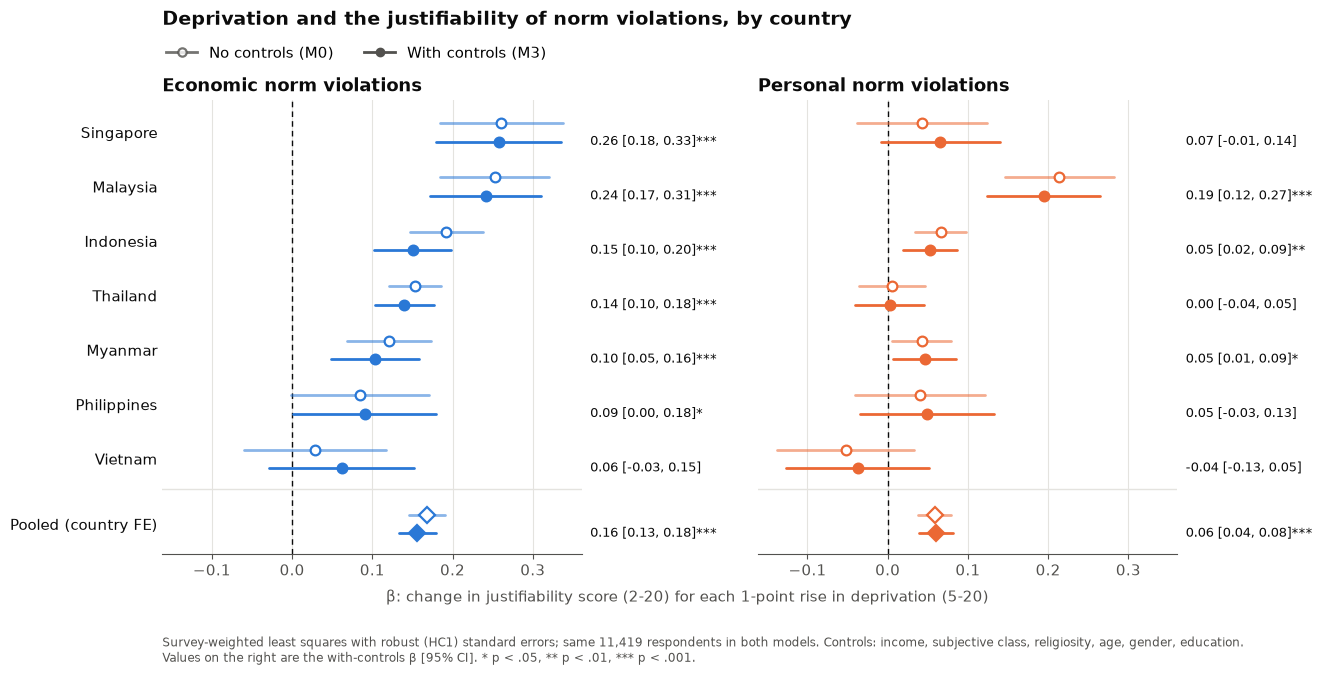

In [84]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

BLUE, ORANGE, INK, MUTED, GRID = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.spines.left': False, 'axes.edgecolor': MUTED, 'xtick.color': MUTED,
                     'ytick.color': INK, 'axes.labelcolor': MUTED})
FIG = '../output/figures/'
get = lambda country, outcome, step: seq[(seq.country == country) & (seq.outcome == outcome) & (seq.model == step)].iloc[0]

# Rows ordered by the adjusted economic β, pooled estimate at the bottom
row_order = (seq[(seq.outcome == 'Economic') & (seq.model == FULL) & (seq.country != ALL)]
             .sort_values('beta', ascending=False)['country'].tolist())
row_y = {c: len(row_order) - i for i, c in enumerate(row_order)}
row_y[ALL] = -0.2
row_names = {**country_names, ALL: 'Pooled (country FE)'}


def forest_panel(ax, outcome, color, offset=0.17):
    for country, y in row_y.items():
        pooled = country == ALL
        for step, dy, face in [('M0', offset, 'white'), (FULL, -offset, color)]:
            r = get(country, outcome, step)
            ax.plot([r.ci_low, r.ci_high], [y + dy] * 2, color=color, lw=2,
                    alpha=0.55 if step == 'M0' else 1, solid_capstyle='round', zorder=2)
            ax.plot(r.beta, y + dy, marker='D' if pooled else 'o', ms=8 if pooled else 7, mfc=face,
                    mec=color, mew=1.6, ls='none', zorder=3)
        a = get(country, outcome, FULL)
        ax.text(1.02, y - offset, f'{a.beta:.2f} [{a.ci_low:.2f}, {a.ci_high:.2f}]{stars(a.p)}',
                transform=ax.get_yaxis_transform(), va='center', fontsize=9.5, color=INK)
    ax.axvline(0, color=INK, lw=1, ls=(0, (4, 3)), zorder=1)
    ax.axhline(0.45, color=GRID, lw=1)
    ax.grid(axis='x', color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.set_yticks(list(row_y.values()), [row_names[c] for c in row_y])
    ax.tick_params(axis='y', length=0)
    ax.set_ylim(-0.75, len(row_order) + 0.6)


legend_handles = [
    Line2D([], [], marker='o', mfc='white', mec=MUTED, mew=1.6, color=MUTED, alpha=0.8, lw=2, label='No controls (M0)'),
    Line2D([], [], marker='o', mfc=MUTED, mec=MUTED, color=MUTED, lw=2, label=f'With controls ({FULL})'),
]
ctrl_note = 'income, subjective class, religiosity, age, gender, education'
footnote = (f'Survey-weighted least squares with robust (HC1) standard errors; same {len(analysis):,} respondents in both models. '
            f'Controls: {ctrl_note}.\nValues on the right are the with-controls β [95% CI]. '
            '* p < .05, ** p < .01, *** p < .001.')

fig, axes = plt.subplots(1, 2, figsize=(14, 6.4), sharex=True, sharey=True, gridspec_kw={'wspace': 0.42})
forest_panel(axes[0], 'Economic', BLUE)
forest_panel(axes[1], 'Personal', ORANGE)
axes[0].set_title('Economic norm violations', loc='left', fontweight='bold', color=INK)
axes[1].set_title('Personal norm violations', loc='left', fontweight='bold', color=INK)
fig.supxlabel('β: change in justifiability score (2-20) for each 1-point rise in deprivation (5-20)', color=MUTED, fontsize=11, y=0.07)
fig.suptitle('Deprivation and the justifiability of norm violations, by country', x=0.125, ha='left', fontsize=14, fontweight='bold', color=INK, y=1.0)
fig.legend(handles=legend_handles, loc='upper left', bbox_to_anchor=(0.118, 0.965), ncol=2, frameon=False)
fig.text(0.125, -0.025, footnote, fontsize=8.5, color=MUTED, va='bottom')
fig.subplots_adjust(top=0.86, bottom=0.15, right=0.85)
plt.savefig(FIG + 'forest_deprivation_by_country.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

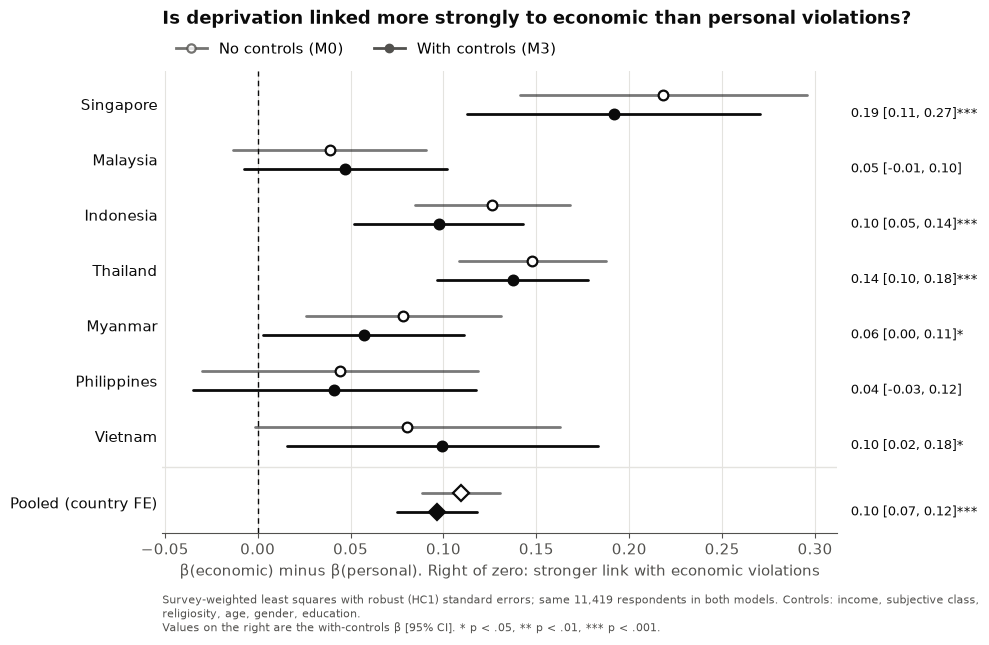

In [85]:
# Forest plot for the research question: economic minus personal
# Right of zero = deprivation is linked more strongly to economic than to personal violations
fig, ax = plt.subplots(figsize=(10, 6))
forest_panel(ax, 'Gap', INK)
ax.set_title('Is deprivation linked more strongly to economic than personal violations?', loc='left', fontweight='bold', color=INK, pad=34)
ax.set_xlabel('β(economic) minus β(personal). Right of zero: stronger link with economic violations')
ax.legend(handles=legend_handles, loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, frameon=False)
fig.text(0.125, -0.06, footnote, fontsize=8, color=MUTED, va='bottom', wrap=True)
fig.subplots_adjust(right=0.8)
plt.savefig(FIG + 'forest_economic_minus_personal.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

## Step 5: Other new visuals

**What predicts each outcome?** All predictors are standardised, so each estimate is the change in justifiability for a 1 SD rise in that predictor. This shows how deprivation compares with the controls.

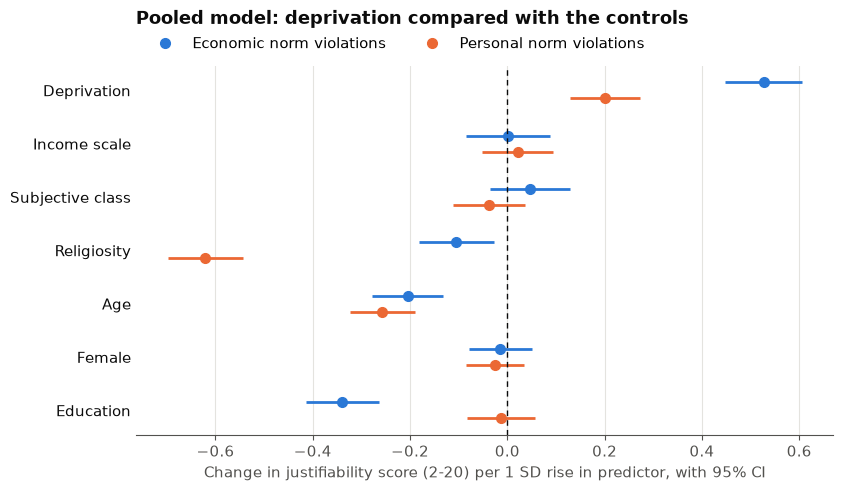

outcome           Economic  Personal
predictor                           
Age                 -0.205    -0.257
Deprivation          0.527     0.201
Education           -0.339    -0.013
Female              -0.015    -0.025
Income scale         0.001     0.021
Religiosity         -0.105    -0.621
Subjective class     0.047    -0.038


In [86]:
z = analysis.copy()
predictors = [IV] + all_controls
z[predictors] = (z[predictors] - z[predictors].mean()) / z[predictors].std()
labels = {IV: 'Deprivation', 'income': 'Income scale', 'subj_class': 'Subjective class', 'religiosity': 'Religiosity',
          'age': 'Age', 'female': 'Female', 'education': 'Education'}

std_rows = []
for label, color, dy in [('Economic', BLUE, 0.15), ('Personal', ORANGE, -0.15)]:
    m = smf.wls(f"{DVS[label]} ~ {' + '.join(predictors)} + {COUNTRY_FE}", data=z, weights=z['W_WEIGHT']).fit(cov_type='HC1', use_t=True)
    ci = m.conf_int()
    for p in predictors:
        std_rows.append({'outcome': label, 'predictor': labels[p], 'beta_per_sd': m.params[p],
                         'ci_low': ci.loc[p, 0], 'ci_high': ci.loc[p, 1], 'p': m.pvalues[p]})
std_coef = pd.DataFrame(std_rows)
std_coef.to_csv('../output/tables/ols_controls_standardised_coefficients.csv', index=False)

fig, ax = plt.subplots(figsize=(9, 4.8))
ypos = {labels[p]: len(predictors) - i for i, p in enumerate(predictors)}
for label, color, dy in [('Economic', BLUE, 0.15), ('Personal', ORANGE, -0.15)]:
    d = std_coef[std_coef.outcome == label]
    y = d['predictor'].map(ypos) + dy
    ax.hlines(y, d['ci_low'], d['ci_high'], color=color, lw=2)
    ax.plot(d['beta_per_sd'], y, 'o', color=color, ms=7, label=f'{label} norm violations')
ax.axvline(0, color=INK, lw=1, ls=(0, (4, 3)))
ax.grid(axis='x', color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.set_yticks(list(ypos.values()), list(ypos))
ax.tick_params(axis='y', length=0)
ax.set_xlabel('Change in justifiability score (2-20) per 1 SD rise in predictor, with 95% CI')
ax.set_title('Pooled model: deprivation compared with the controls', loc='left', fontweight='bold', color=INK, pad=30)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, frameon=False)
plt.savefig(FIG + 'pooled_standardised_coefficients.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print(std_coef.pivot(index='predictor', columns='outcome', values='beta_per_sd').round(3).to_string())

**Adjusted regression lines.** The earlier line charts with controls and confidence bands added. Each line is the predicted score across deprivation levels, with the controls held at that country's weighted mean.

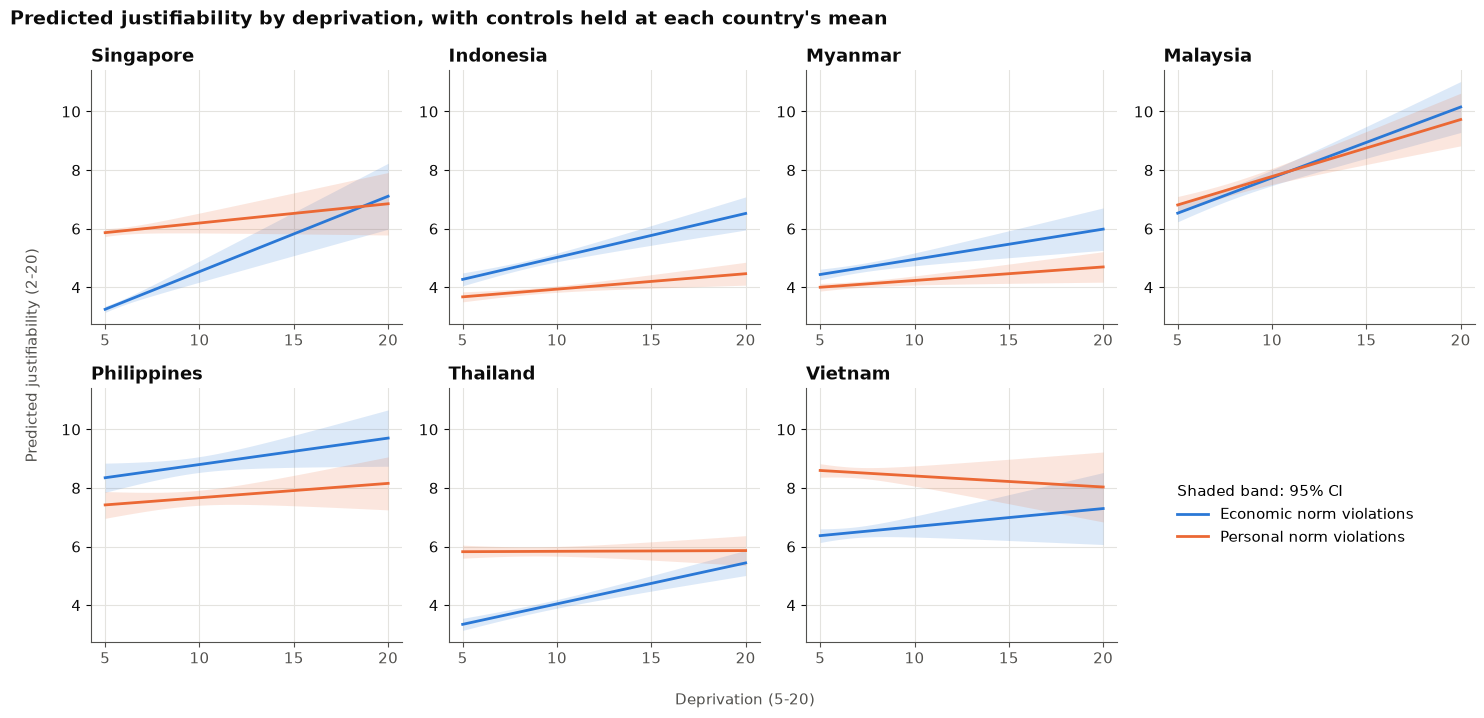

In [87]:
grid = np.linspace(5, 20, 50)
panel_order = ['SGP', 'IDN', 'MMR', 'MYS', 'PHL', 'THA', 'VNM']
fig, axes = plt.subplots(2, 4, figsize=(15, 7.2), sharex=True, sharey=True)
axes = axes.ravel()
for ax, c in zip(axes, panel_order):
    data = analysis[analysis['country'] == c]
    held = {v: np.average(data[v], weights=data['W_WEIGHT']) for v in all_controls}
    new_x = pd.DataFrame({IV: grid, **held})
    for label, color in [('Economic', BLUE), ('Personal', ORANGE)]:
        pred = models[(c, label, FULL)].get_prediction(new_x, weights=1).summary_frame(alpha=0.05)
        ax.fill_between(grid, pred['mean_ci_lower'], pred['mean_ci_upper'], color=color, alpha=0.16, lw=0)
        ax.plot(grid, pred['mean'], color=color, lw=2)
    ax.set_title(country_names[c], loc='left', fontweight='bold', color=INK)
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.spines['left'].set_visible(True)
    ax.tick_params(labelbottom=True, labelleft=True)
axes[-1].axis('off')
axes[-1].legend(handles=[Line2D([], [], color=BLUE, lw=2, label='Economic norm violations'),
                         Line2D([], [], color=ORANGE, lw=2, label='Personal norm violations')],
                loc='center left', frameon=False, title='Shaded band: 95% CI', alignment='left')
fig.supxlabel('Deprivation (5-20)', color=MUTED, fontsize=11)
fig.supylabel('Predicted justifiability (2-20)', color=MUTED, fontsize=11)
fig.suptitle('Predicted justifiability by deprivation, with controls held at each country\'s mean', x=0.01, ha='left', fontsize=14, fontweight='bold', color=INK)
fig.tight_layout(rect=(0.012, 0, 1, 1))
plt.savefig(FIG + 'adjusted_regression_lines_by_country.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

## Step 6: Robustness checks for deprivation and the justifiability scores

Each check changes one choice in the analysis and asks whether the main finding still holds: **β on deprivation is positive and significant, and larger for economic than personal violations** (a significant positive gap). All checks use the full model's controls (M3), and the pooled models include effect-coded country fixed effects.

| Check | Concern it addresses |
|---|---|
| **A. Rank-based model** | The justifiability scores are skewed (most respondents answer "never justifiable"), and OLS treats the scales as exact, evenly spaced numbers |
| **B. Deprivation items one at a time** | The deprivation index combines four items, and its reliability is lower in some countries (α .61-.66), so one item could be driving the result |

In [88]:
def fit_any(dv, iv_terms, controls, data, country_effects=False):
    '''Survey-weighted least squares with robust (HC1) SEs, for any predictor(s).'''
    rhs = list(iv_terms) + list(controls) + ([COUNTRY_FE] if country_effects else [])
    return smf.wls(f"{dv} ~ {' + '.join(rhs)}", data=data, weights=data['W_WEIGHT']).fit(cov_type='HC1', use_t=True)


def coef_row(m, term, **labels):
    lo, hi = m.conf_int().loc[term]
    return {**labels, 'beta': m.params[term], 'ci_low': lo, 'ci_high': hi, 'p': m.pvalues[term], 'n': int(m.nobs)}


fmt = lambda r: f"{r.beta:.3f}{stars(r.p)} [{r.ci_low:.3f}, {r.ci_high:.3f}]"


### A. Rank-based model

Justifiability and deprivation are each converted to **percentile ranks within each country** (0 = lowest, 100 = highest; ties share the average rank). Ranks keep only the order of respondents, so the skew and the exact spacing of the scales no longer matter, and a few very high scores cannot pull the estimate.

**Reading β:** the change in a respondent's percentile rank on justifiability for each 1-percentile rise in deprivation rank. Economic and personal outcomes are now on the same 0-100 scale, so the gap is still a direct comparison. β here is not on the same scale as the main models, so compare direction and significance, not size.

In [89]:
rk = analysis.copy()
pct_rank = lambda col: rk.groupby('country')[col].rank(method='average', pct=True) * 100
rk['dep_rank'] = pct_rank(IV)
rk['EV_rank'] = pct_rank('EV_rebased20')
rk['PV_rank'] = pct_rank('PV_rebased20')
rk['gap_rank'] = rk['EV_rank'] - rk['PV_rank']
RANK_DVS = {'Economic': 'EV_rank', 'Personal': 'PV_rank', 'Gap': 'gap_rank'}

rank_rows = []
for label, dv in RANK_DVS.items():
    for country, data in [(c, g) for c, g in rk.groupby('country')] + [(ALL, rk)]:
        m = fit_any(dv, ['dep_rank'], all_controls, data, country_effects=(country == ALL))
        rank_rows.append(coef_row(m, 'dep_rank', country=country, outcome=label))
rank_res = pd.DataFrame(rank_rows)
rank_res.to_csv('../output/tables/robustness_rank_based.csv', index=False)

# Side by side with the main model: does each result keep its direction and significance?
main = seq[seq['model'] == FULL].set_index(['country', 'outcome'])
rank_cmp = rank_res.set_index(['country', 'outcome'])
sig = lambda b, p: 'positive, sig.' if (p < .05 and b > 0) else 'negative, sig.' if p < .05 else 'not sig.'
compare = pd.DataFrame({
    'main β (OLS)': main['beta'].round(3),
    'main p': main['p'].round(3),
    'rank β': rank_cmp['beta'].round(3),
    'rank p': rank_cmp['p'].round(3),
})
compare['main result'] = [sig(b, p) for b, p in zip(main['beta'], main['p'])]
compare['rank result'] = [sig(b, p) for b, p in zip(rank_cmp['beta'], rank_cmp['p'])]
compare['same conclusion'] = compare['main result'] == compare['rank result']
compare = compare.reindex(rank_cmp.index)
print(compare.sort_index(level=['outcome', 'country']).to_string())
print(f"\nSame conclusion in {compare['same conclusion'].sum()} of {len(compare)} results")

                  main β (OLS)  main p  rank β  rank p     main result     rank result  same conclusion
country outcome                                                                                        
IDN     Economic         0.150   0.000   0.148   0.000  positive, sig.  positive, sig.             True
MMR     Economic         0.103   0.000   0.104   0.002  positive, sig.  positive, sig.             True
MYS     Economic         0.242   0.000   0.221   0.000  positive, sig.  positive, sig.             True
PHL     Economic         0.090   0.048   0.092   0.009  positive, sig.  positive, sig.             True
Pooled  Economic         0.156   0.000   0.177   0.000  positive, sig.  positive, sig.             True
SGP     Economic         0.257   0.000   0.261   0.000  positive, sig.  positive, sig.             True
THA     Economic         0.140   0.000   0.327   0.000  positive, sig.  positive, sig.             True
VNM     Economic         0.062   0.183   0.041   0.190        no

### B. Deprivation items one at a time

The index is replaced by each item on its own (food, medicine, cash income, shelter), each multiplied by 5 so it is on the same 5-20 scale as the index. β values are therefore directly comparable with the main result. The last row enters all four items together, to show which items still matter once the others are held constant. All models use respondents who answered all four items.

In [90]:
dep_items = {'Q51': 'Food', 'Q53': 'Medicine', 'Q54': 'Cash income', 'Q55': 'Shelter'}
it = analysis.dropna(subset=list(dep_items)).copy()
for q, name in dep_items.items():
    it[f'item_{q}'] = it[q] * 5                      # 1-4 x 5 = 5-20, same scale as the index
item_terms = [f'item_{q}' for q in dep_items]

item_rows = []
for label, dv in DVS.items():
    for country, data in [(c, g) for c, g in it.groupby('country')] + [(ALL, it)]:
        fe = country == ALL
        m = fit_any(dv, [IV], all_controls, data, fe)
        item_rows.append(coef_row(m, IV, country=country, outcome=label, predictor='Index (main)'))
        for q, name in dep_items.items():
            m = fit_any(dv, [f'item_{q}'], all_controls, data, fe)
            item_rows.append(coef_row(m, f'item_{q}', country=country, outcome=label, predictor=name))
        if fe:                                        # all four together, pooled only
            m = fit_any(dv, item_terms, all_controls, data, fe)
            for q, name in dep_items.items():
                item_rows.append(coef_row(m, f'item_{q}', country=country, outcome=label, predictor=f'{name} (all 4 together)'))
item_res = pd.DataFrame(item_rows)
item_res.to_csv('../output/tables/robustness_deprivation_items.csv', index=False)

order = ['Index (main)'] + list(dep_items.values()) + [f'{n} (all 4 together)' for n in dep_items.values()]
pooled_items = item_res[item_res['country'] == ALL].copy()
pooled_items['β [95% CI]'] = pooled_items.apply(fmt, axis=1)
print(f"Pooled, n = {int(pooled_items['n'].iloc[0]):,}")
print(pooled_items.pivot(index='predictor', columns='outcome', values='β [95% CI]').reindex(order)[list(DVS)].to_string())

# How many countries does each item work in? (positive and significant)
by_c = item_res[(item_res['country'] != ALL) & ~item_res['predictor'].str.contains('together')]
count = (by_c.assign(pos_sig=(by_c['beta'] > 0) & (by_c['p'] < .05))
             .pivot_table(index='predictor', columns='outcome', values='pos_sig', aggfunc='sum')
             .reindex(['Index (main)'] + list(dep_items.values()))[list(DVS)])
print('\nNumber of countries (out of 7) where β is positive and significant')
print(count.to_string())
print('\n* p < .05, ** p < .01, *** p < .001')

Pooled, n = 11,398
outcome                                      Economic                 Personal                      Gap
predictor                                                                                              
Index (main)                  0.157*** [0.134, 0.181]  0.059*** [0.038, 0.080]  0.098*** [0.077, 0.120]
Food                          0.095*** [0.077, 0.112]  0.032*** [0.017, 0.047]  0.063*** [0.047, 0.078]
Medicine                      0.079*** [0.063, 0.096]  0.036*** [0.021, 0.051]  0.043*** [0.028, 0.059]
Cash income                   0.068*** [0.053, 0.082]  0.024*** [0.011, 0.037]  0.044*** [0.030, 0.058]
Shelter                       0.101*** [0.079, 0.123]  0.037*** [0.018, 0.056]  0.064*** [0.043, 0.085]
Food (all 4 together)         0.055*** [0.034, 0.075]    0.015 [-0.003, 0.033]  0.040*** [0.021, 0.058]
Medicine (all 4 together)     0.038*** [0.020, 0.057]   0.024** [0.008, 0.040]    0.015 [-0.003, 0.032]
Cash income (all 4 together)    0.021* [0.004

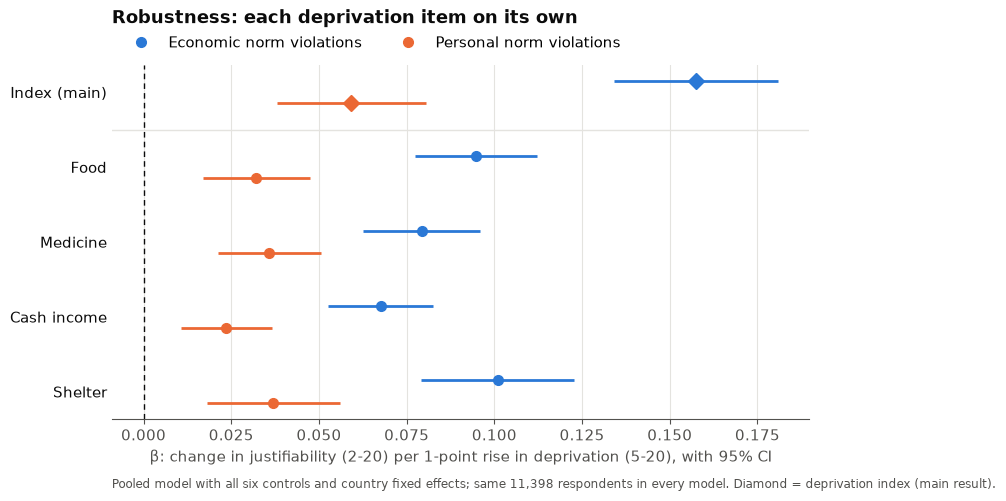

In [91]:
# Forest plot: each deprivation item compared with the index (pooled, full model)
plot_rows = ['Index (main)'] + list(dep_items.values())
ypos = {name: len(plot_rows) - i for i, name in enumerate(plot_rows)}
fig, ax = plt.subplots(figsize=(9, 4.6))
for label, color, dy in [('Economic', BLUE, 0.15), ('Personal', ORANGE, -0.15)]:
    d = pooled_items[(pooled_items['outcome'] == label) & pooled_items['predictor'].isin(plot_rows)]
    y = d['predictor'].map(ypos) + dy
    ax.hlines(y, d['ci_low'], d['ci_high'], color=color, lw=2)
    is_main = d['predictor'] == 'Index (main)'
    ax.plot(d.loc[~is_main, 'beta'], y[~is_main], 'o', color=color, ms=7, label=f'{label} norm violations')
    ax.plot(d.loc[is_main, 'beta'], y[is_main], 'D', color=color, ms=8)
ax.axvline(0, color=INK, lw=1, ls=(0, (4, 3)))
ax.axhline(len(plot_rows) - 0.5, color=GRID, lw=1)
ax.grid(axis='x', color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.set_yticks(list(ypos.values()), list(ypos))
ax.tick_params(axis='y', length=0)
ax.set_xlabel('β: change in justifiability (2-20) per 1-point rise in deprivation (5-20), with 95% CI')
ax.set_title('Robustness: each deprivation item on its own', loc='left', fontweight='bold', color=INK, pad=30)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, frameon=False)
fig.text(0.125, -0.04, f'Pooled model with all six controls and country fixed effects; same {len(it):,} respondents in every model. '
         'Diamond = deprivation index (main result).', fontsize=8.5, color=MUTED)
plt.savefig(FIG + 'robustness_deprivation_items.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

### Verdict

The main finding passes a check if, in the pooled model, β on deprivation is positive and significant for both outcomes and the economic-minus-personal gap is positive and significant.

In [92]:
def verdict(df, predictor_col=None, name=None):
    d = df[df['country'] == ALL]
    if predictor_col:
        d = d[d[predictor_col] == name]
    d = d.set_index('outcome')
    ok = lambda o: d.loc[o, 'beta'] > 0 and d.loc[o, 'p'] < .05
    return {'Economic +, sig.': ok('Economic'), 'Personal +, sig.': ok('Personal'), 'Gap +, sig.': ok('Gap')}


checks = {'Main model (M3)': verdict(seq[seq['model'] == FULL]),
          'A. Rank-based': verdict(rank_res)}
for name in dep_items.values():
    checks[f'B. {name} only'] = verdict(item_res, 'predictor', name)
verdicts = pd.DataFrame(checks).T
verdicts['Finding holds'] = verdicts.all(axis=1)
verdicts.to_csv('../output/tables/robustness_verdicts.csv')
print(verdicts.replace({True: 'yes', False: 'NO'}).to_string())

                    Economic +, sig. Personal +, sig. Gap +, sig. Finding holds
Main model (M3)                  yes              yes         yes           yes
A. Rank-based                    yes              yes         yes           yes
B. Food only                     yes              yes         yes           yes
B. Medicine only                 yes              yes         yes           yes
B. Cash income only              yes              yes         yes           yes
B. Shelter only                  yes              yes         yes           yes


## Step 7: What the results show

*Figures below are from the full model, M3.*

**Main finding.** Deprivation is linked more strongly to the justifiability of economic violations (pooled β = 0.16, 95% CI [0.13, 0.18]) than personal violations (β = 0.06, [0.04, 0.08]). The gap is 0.10 [0.07, 0.12]. It is positive in all seven countries and statistically significant in five: not in Malaysia or the Philippines.

**Effect of the controls.** The pooled economic β falls by 7% from M0 to M3, most of it when age, gender and education are added. The pooled personal β rises by 1%. The association survives all six controls, so these variables do not explain it away. Income and subjective class stay close to zero once deprivation is in the model, which fits our argument that insecurity is distinct from income level.

**Results that are sensitive to the model**
- **Singapore, personal norms:** β is 0.04 (p = .31) with no controls, 0.10 (p = .02) in M2, and 0.07 (p = .08) in M3. This should not be reported as a firm finding.
- **Philippines, economic norms:** significant in M3, but only just (p = .048), and p = .054 with no controls.
- **Vietnam, gap:** p = .054 with no controls and p = .02 in M3.
- **Indonesia:** β falls by about 20% on both outcomes, the largest drop among the countries with a significant effect, but both remain significant.

**Country differences.** Slopes differ across countries for both outcomes (joint tests p ≤ .001). On economic violations, Singapore's slope is significantly steeper than every country's except Malaysia's. On personal violations, Malaysia's slope stands out, significantly steeper than Singapore's and the only large one (0.19). Deprivation is significantly related to personal norms only in Indonesia, Malaysia and Myanmar. Vietnam is the only country where it is not significantly related to economic norms.

**Controls as predictors (pooled, per SD)**
- **Religiosity** is the strongest predictor of personal norms (-0.62).
- **Education** matters for economic norms (-0.34) but not personal norms (-0.01). Deprivation (0.53) remains the strongest predictor of economic norms.
- **Age:** older respondents find both kinds of violation less justifiable (-0.21 economic, -0.26 personal).
- **Gender** is not significantly related to either outcome.

**Robustness (Step 6).** The pooled finding passes both checks: deprivation is positive and significant for both outcomes, with a significant positive gap, in every version.
- **Rank-based model:** using percentile ranks, so the skewed scores and the exact spacing of the scales no longer matter, gives the same pooled conclusion. The gap is 0.105 percentile points per percentile of deprivation (p < .001). Country by country, 18 of 24 results keep the same conclusion. The country gaps are the least stable: Indonesia, Myanmar and Vietnam lose significance, while Malaysia gains it. Personal-norms βs become significant in Singapore and the Philippines.
- **Deprivation items one at a time:** each of the four items on its own (food, medicine, cash income, shelter) gives a positive, significant β for both outcomes and a significant gap, so no single item drives the result. Each item's β is smaller than the index's because one item is a noisier measure of deprivation than the average of four. Entered together, food and shelter carry the most unique weight for economic norms.

**Limitations**
- The data are cross-sectional, so results are associations and do not show that deprivation causes these attitudes.
- Other confounders may remain unmeasured.
- Religiosity could be partly a result of insecurity and not only a confounder. The stepwise table shows the effect of including it.
- The religiosity index has low reliability within several countries (α = .11 in Indonesia, .22 in Myanmar). See the robustness table for β with its items entered separately.
- Economic violations α is .59 in Myanmar, so that country's economic scale is measured less reliably.
- Education uses the ISCED 0-8 codes as an interval scale, and some countries have no respondents at certain levels (for example ISCED 4 in Indonesia and ISCED 3 in Malaysia).
- Rebasing multiplies each scale up to a maximum of 20, but the scales have different minimums, so β values for different predictors are best compared per SD.
- Robust standard errors do not account for clustered sampling, because PSU codes are missing for Malaysia and Singapore. Confidence intervals may be somewhat too narrow.
- Most variance explained in the pooled models comes from country fixed effects. Within individual countries, R² is usually below .09, with Singapore's personal-norms model the exception at .26.
- Assumptions: OLS assumes a linear relationship, including for age, and treats income and class as interval scales. The DVs are right-skewed; the rank-based check shows the pooled finding does not depend on this, but country-level gaps are less stable.
